# Figure 1

Panels C–G: measured and fitted temporal filters, PCA, half-life time scale, feature space and temporal diversity coefficient.

**Data.** Requires `ALL_RESPONSES.npy`, the measured responses of Currier & Clandinin, *Cell* 188 (2025), downloaded from that publication. Set `PATH_CLANDININ` to its folder.

**Fit parameters.** `FitParameters/` contains the parameters of Eq. 4 fitted to the measured mean filters, and the 30 filters per cell type.

In [ ]:
import colorsys
import re
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.signal import savgol_filter
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

matplotlib.rcParams['font.family']      = 'sans-serif'
matplotlib.rcParams['font.sans-serif']  = ['Arial']
matplotlib.rcParams['font.size']        = 12
matplotlib.rcParams['pdf.fonttype']     = 42
matplotlib.rcParams['ps.fonttype']      = 42
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm']      = 'Arial'
matplotlib.rcParams['mathtext.it']      = 'Arial:italic'

# Paths
PATH_CLANDININ = Path('Clandinin_data') # Define it
PATH_PARAMS    = Path('FitParameters')
PATH_PDF       = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237',
             'green': '#808233', 'yellow': '#f6eb16', 'orange': '#faa51a'}

CELL_TYPES     = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm2', 'Tm1', 'Tm4', 'Tm9']
DOUBLE_POLARITY = ['L1', 'L2', 'Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
N_TYPES        = len(CELL_TYPES)

polarity_of       = {ct: ('double' if ct in DOUBLE_POLARITY else 'single') for ct in CELL_TYPES}
color_by_polarity = {'double': COLOR_REF['blue'], 'single': COLOR_REF['red']}
polarity_name     = {'double': 'Double-polarity', 'single': 'Single-polarity'}

pathways = {'Lamina':      ['L1', 'L2', 'L3'],
            'Medulla ON':  ['Mi4', 'Tm3', 'Mi1', 'Mi9'],
            'Medulla OFF': ['Tm9', 'Tm1', 'Tm2', 'Tm4']}
color_by_pathway = {'Lamina': COLOR_REF['green'], 'Medulla ON': COLOR_REF['yellow'],
                    'Medulla OFF': COLOR_REF['orange']}


def shade(hex_color, factor, dhue=0.0):
    r, g, b = matplotlib.colors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    return colorsys.hls_to_rgb((h + dhue / 360.0) % 1.0, float(np.clip(l * factor, 0.05, 0.88)), s)


# (lightness factor, hue shift) of each cell type within its pathway colour
shade_steps = {'Lamina':      [(1.45, 8), (1.0, 0), (0.62, 6)],
               'Medulla ON':  [(1.0, 0), (0.86, -6), (0.72, -12), (0.60, -16)],
               'Medulla OFF': [(1.18, 2), (1.0, 0), (0.80, -6), (0.62, -2)]}
color_by_type = {ct: shade(color_by_pathway[g], f, dh)
                 for g, members in pathways.items()
                 for ct, (f, dh) in zip(members, shade_steps[g])}


def strip_spines(ax, keep=('left', 'bottom')):
    for side in ('top', 'right', 'left', 'bottom'):
        ax.spines[side].set_visible(side in keep)


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


def filter_area(t, h):                       # Eq. 5
    return np.sum(0.5 * (h[1:] + h[:-1]) * np.diff(t))


def half_life(t, h):                         # Eq. 6
    cum = np.cumsum(0.5 * (np.abs(h[1:]) + np.abs(h[:-1])) * np.diff(t))
    return t[np.where(cum >= cum[-1] / 2)[0][0]]


t_fine = np.arange(0.001, 5, 0.001)          # s, grid for A and tau_L
t_pca  = np.arange(0.01, 5, 0.01)            # s, grid for the PCA

## Measured filters

In [3]:
data   = np.load(PATH_CLANDININ / 'ALL_RESPONSES.npy', allow_pickle=True).item()
t_data = -data['STRF_time'][::-1]            # s, the 60 sample times of the measured filters

SAVGOL_WINDOW, SAVGOL_ORDER = 7, 4


def preprocess(trace):
    # time-reversed, F(0) = 0, Savitzky-Golay smoothing, sign-aligned
    x      = trace[::-1] - trace[-1]
    padded = np.concatenate([-x[1:SAVGOL_WINDOW + 1][::-1], x])
    x      = savgol_filter(padded, SAVGOL_WINDOW, SAVGOL_ORDER)[SAVGOL_WINDOW:]
    x      = x - x[0]
    return -x if np.abs(np.max(x)) < np.abs(np.min(x)) else x


def cell_traces(ct):
    # one trace per recorded cell: mean of its centre-pixel blue and UV channels
    out = []
    for i in np.where(data['cell_types'] == ct)[0]:
        chans = [a for a in (data['blue_STRFs'][39, 39, :, i], data['uv_STRFs'][39, 39, :, i])
                 if not np.all(np.isnan(a))]
        if chans:
            out.append(preprocess(np.mean(chans, axis=0)))
    return np.array(out)


measured_mean = {}
for ct in CELL_TYPES:
    m = cell_traces(ct).mean(axis=0)
    measured_mean[ct] = m / np.max(np.abs(m))

## Fitted filters and their 30 realizations

In [4]:
fit_params = {}
with open(PATH_PARAMS / 'MeasuredFilters_FitParameters.txt') as fh:
    for line in fh:
        if not line.startswith('#'):
            ct, *p = line.split()
            fit_params[ct] = np.array(p, float)

gen_types, gen_params = [], []
with open(PATH_PARAMS / 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt') as fh:
    for line in fh:
        if line.strip() and not line.startswith('#'):
            fields = line.split()
            gen_types.append(fields[0])
            gen_params.append([float(f) for f in fields[6:9]])     # tau1, tau2, rho_
gen_types    = np.array(gen_types)
gen_polarity = np.array([polarity_of[ct] for ct in gen_types])

h_gen   = np.array([filter_function(t_pca, *p) for p in gen_params])
A_gen   = np.array([filter_area(t_fine, filter_function(t_fine, *p)) for p in gen_params])
tau_gen = np.array([half_life(t_fine, filter_function(t_fine, *p)) for p in gen_params])

h_fit   = np.array([filter_function(t_pca, *fit_params[ct]) for ct in CELL_TYPES])
A_fit   = np.array([filter_area(t_fine, filter_function(t_fine, *fit_params[ct])) for ct in CELL_TYPES])
tau_fit = np.array([half_life(t_fine, filter_function(t_fine, *fit_params[ct])) for ct in CELL_TYPES])

## Fig. 1C

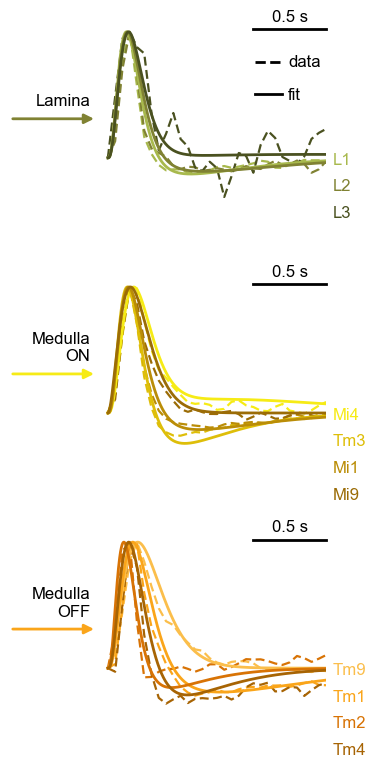

In [5]:
T_STOP    = 1.5      # s
SCALE_LEN = 0.5      # s

m_fit  = t_fine <= T_STOP
m_data = t_data <= T_STOP + 1e-9

Fig, axes = plt.subplots(len(pathways), 1, figsize=(4.2, 7.6), sharex=True)
Fig.subplots_adjust(left=0.27, right=0.80, top=0.97, bottom=0.03, hspace=0.25)

for ax, (pathway, members) in zip(axes, pathways.items()):
    for ct in members:
        ax.plot(t_data[m_data], measured_mean[ct][m_data], color=color_by_type[ct], linewidth=1.6,
                linestyle='--', dashes=(4, 2), zorder=3)
        ax.plot(t_fine[m_fit], filter_function(t_fine, *fit_params[ct])[m_fit],
                color=color_by_type[ct], linewidth=2.0, zorder=4)

    strip_spines(ax, keep=())
    ax.tick_params(bottom=False, labelbottom=False, left=False, labelleft=False)
    ax.set_xlim(-0.03, T_STOP)
    ax.set_ylim(-0.5, 1.12)

    ax.annotate(pathway.replace(' ', '\n'), xy=(-0.06, 0.55), xycoords='axes fraction',
                ha='right', va='bottom')
    ax.annotate('', xy=(-0.03, 0.5), xytext=(-0.42, 0.5), xycoords='axes fraction',
                arrowprops=dict(arrowstyle='-|>', color=color_by_pathway[pathway], lw=2.0,
                                mutation_scale=14))
    for k, ct in enumerate(members):
        ax.text(1.03, 0.30 - 0.13 * k, ct, transform=ax.transAxes, color=color_by_type[ct],
                ha='left', va='center')

    ax.plot([T_STOP - SCALE_LEN, T_STOP], [1.02, 1.02], color='k', linewidth=2.0, clip_on=False)
    ax.text(T_STOP - SCALE_LEN / 2, 1.06, f'{SCALE_LEN:g} s', ha='center', va='bottom')

ax = axes[0]
for y, (ls, text) in zip((0.78, 0.62), (('--', 'data'), ('-', 'fit'))):
    ax.plot([0.68, 0.80], [y, y], color='k', linewidth=2.0, linestyle=ls, transform=ax.transAxes)
    ax.text(0.83, y, text, transform=ax.transAxes, ha='left', va='center')

Fig.savefig(PATH_PDF / 'Fig1C_TemporalFilters.pdf', bbox_inches='tight')
plt.show()

## Fig. 1D

Explained variance ratios: [0.815 0.143 0.029]
ARI (k = 2) = 1.000


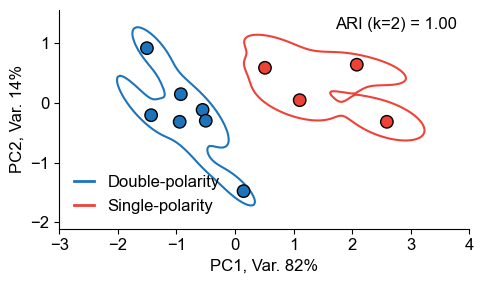

In [6]:
pca   = PCA(n_components=3)
X_gen = pca.fit_transform(h_gen)
X_fit = pca.transform(h_fit)
print('Explained variance ratios:', np.round(pca.explained_variance_ratio_, 3))

clusters = fcluster(linkage(X_gen, method='ward'), t=2, criterion='maxclust')
ari      = adjusted_rand_score(gen_polarity, clusters)
print(f'ARI (k = 2) = {ari:.3f}')

PC2_SIGN = -1                                # sign of a principal component is arbitrary
x_gen, y_gen = X_gen[:, 0], PC2_SIGN * X_gen[:, 1]
xx, yy = np.mgrid[x_gen.min() - 2.0:x_gen.max() + 2.0:200j,
                  y_gen.min() - 0.5:y_gen.max() + 0.5:200j]

Fig, ax = plt.subplots(1, figsize=(5.0, 3.0))
ax.set_xlim(-3, 4)
for polarity, color in color_by_polarity.items():
    mask    = gen_polarity == polarity
    density = gaussian_kde(np.vstack([x_gen[mask], y_gen[mask]]))(
        np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contour(xx, yy, density, levels=[0.12 * density.max()], colors=color, linewidths=1.5)
ax.scatter(X_fit[:, 0], PC2_SIGN * X_fit[:, 1],
           c=[color_by_polarity[polarity_of[ct]] for ct in CELL_TYPES], s=80, edgecolor='k', zorder=3)

strip_spines(ax)
ax.set_xlabel(f'PC1, Var. {pca.explained_variance_ratio_[0] * 100:.0f}%')
ax.set_ylabel(f'PC2, Var. {pca.explained_variance_ratio_[1] * 100:.0f}%')
ax.text(0.97, 0.97, f'ARI (k=2) = {ari:.2f}', transform=ax.transAxes, va='top', ha='right')
ax.legend(handles=[Line2D([0], [0], color=color_by_polarity[p], lw=2, label=polarity_name[p])
                   for p in ('double', 'single')], frameon=False, loc=3, handlelength=1.2)
plt.tight_layout()
Fig.savefig(PATH_PDF / 'Fig1D_PCA.pdf', bbox_inches='tight')
plt.show()

## Fig. 1E

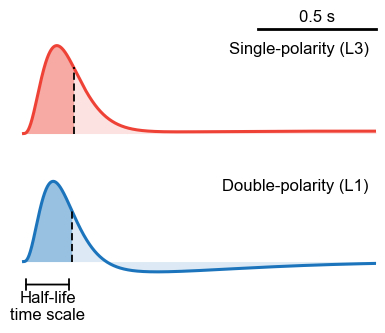

In [7]:
EXAMPLE_TYPES = {'single': 'L3', 'double': 'L1'}

Fig, axes = plt.subplots(2, 1, figsize=(3.8, 3.6))
Fig.subplots_adjust(left=0.04, right=0.98, top=0.90, bottom=0.24, hspace=0.35)

for ax, (polarity, ct) in zip(axes, EXAMPLE_TYPES.items()):
    color = color_by_polarity[polarity]
    h     = filter_function(t_fine, *fit_params[ct])
    tau   = half_life(t_fine, h)
    m     = t_fine <= T_STOP
    t, y  = t_fine[m], h[m]

    ax.fill_between(t, 0, y, where=t <= tau, color=color, alpha=0.45, linewidth=0, zorder=2)
    ax.fill_between(t, 0, y, where=t >= tau, color=color, alpha=0.15, linewidth=0, zorder=2)
    ax.plot(t, y, color=color, linewidth=2.2, zorder=4)
    ax.plot([tau, tau], [0, np.interp(tau, t, y)], color='k', linewidth=1.3, linestyle='--',
            dashes=(4, 2), zorder=5)

    ax.text(0.98, 0.95, f'{polarity_name[polarity]} ({ct})', transform=ax.transAxes,
            ha='right', va='top')
    strip_spines(ax, keep=())
    ax.tick_params(bottom=False, labelbottom=False, left=False, labelleft=False)
    ax.set_xlim(-0.02, T_STOP)
    ax.set_ylim(min(-0.05, 1.25 * y.min()), 1.1)

ax  = axes[1]
tau = half_life(t_fine, filter_function(t_fine, *fit_params[EXAMPLE_TYPES['double']]))
ax.annotate('', xy=(0, -0.10), xytext=(tau, -0.10), xycoords=ax.get_xaxis_transform(),
            textcoords=ax.get_xaxis_transform(), annotation_clip=False,
            arrowprops=dict(arrowstyle='|-|', color='k', lw=1.3, mutation_scale=4))
ax.text(tau / 2, -0.16, 'Half-life\ntime scale', transform=ax.get_xaxis_transform(),
        ha='center', va='top')
ax = axes[0]
ax.plot([T_STOP - SCALE_LEN, T_STOP], [1.08, 1.08], color='k', linewidth=2.0, clip_on=False,
        transform=ax.get_xaxis_transform())
ax.text(T_STOP - SCALE_LEN / 2, 1.12, f'{SCALE_LEN:g} s', transform=ax.get_xaxis_transform(),
        ha='center', va='bottom')

Fig.savefig(PATH_PDF / 'Fig1E_HalfLifeTimeScale.pdf', bbox_inches='tight')
plt.show()

## Fig. 1F

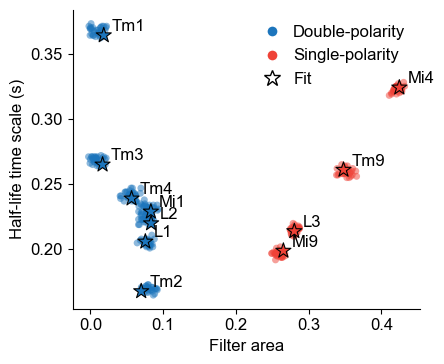

In [8]:
Fig, ax = plt.subplots(1, figsize=(4.6, 3.8))
ax.scatter(A_gen, tau_gen, c=[color_by_polarity[p] for p in gen_polarity], s=25, alpha=0.5,
           marker='o', edgecolor='none', zorder=2)
ax.scatter(A_fit, tau_fit, c=[color_by_polarity[polarity_of[ct]] for ct in CELL_TYPES], s=130,
           marker='*', edgecolor='k', linewidth=0.8, zorder=3)
for i, ct in enumerate(CELL_TYPES):
    ax.annotate(ct, (A_fit[i], tau_fit[i]), textcoords='offset points', xytext=(6, 3), zorder=4)

strip_spines(ax)
ax.set_xlabel('Filter area')
ax.set_ylabel('Half-life time scale (s)')
ax.legend(handles=[
    *[Line2D([0], [0], marker='o', color='w', markerfacecolor=color_by_polarity[p], markersize=8,
             label=polarity_name[p]) for p in ('double', 'single')],
    Line2D([0], [0], marker='*', color='w', markerfacecolor='w', markeredgecolor='k',
           markersize=12, label='Fit')], frameon=False, loc='upper right', handletextpad=0.3)
plt.tight_layout()
Fig.savefig(PATH_PDF / 'Fig1F_AreaVsHalfLife.pdf', bbox_inches='tight')
plt.show()

## Fig. 1G

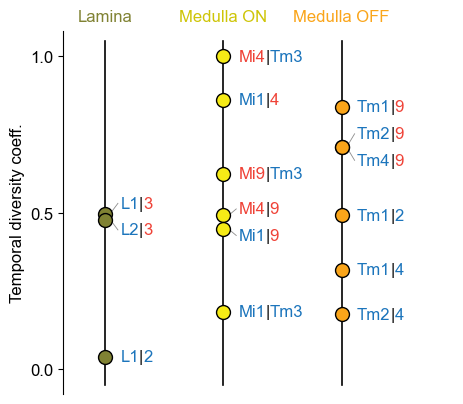

In [9]:
A_of   = dict(zip(CELL_TYPES, A_fit))
tau_of = dict(zip(CELL_TYPES, tau_fit))

d_ij = {}
for pathway, members in pathways.items():
    pairs = list(combinations(members, 2))
    d_ij[pathway] = (np.array([np.hypot(A_of[a] - A_of[b], tau_of[a] - tau_of[b]) for a, b in pairs]),
                     pairs)
d_max     = max(np.max(d) for d, _ in d_ij.values())
diversity = {g: (d / d_max, pairs) for g, (d, pairs) in d_ij.items()}     # D_F, Eq. 24


def split_name(ct):
    m = re.match(r'([A-Za-z]+)(\d+)', ct)
    return m.group(1), int(m.group(2))


def pair_tokens(a, b):
    # 'L1', '3' for {L1, L3}; 'Mi1', 'Tm3' for {Mi1, Tm3}
    a, b = sorted((a, b), key=split_name)
    return a, (b[len(split_name(b)[0]):] if split_name(a)[0] == split_name(b)[0] else b), b


def spread(y, min_sep, n_iter=500):
    # label positions at least min_sep apart
    y = np.array(y, float)
    order = np.argsort(y)
    ys = y[order]
    for _ in range(n_iter):
        gaps = np.diff(ys)
        if np.all(gaps >= min_sep - 1e-9):
            break
        for i in np.where(gaps < min_sep)[0]:
            push = 0.5 * (min_sep - gaps[i])
            ys[i] -= push
            ys[i + 1] += push
    out = np.empty_like(y)
    out[order] = ys
    return out


X_LABEL, MIN_SEP = 0.13, 0.085

Fig, ax = plt.subplots(1, figsize=(4.8, 4.2))
for x, (pathway, (D_F, pairs)) in enumerate(diversity.items()):
    ax.plot([x, x], [-0.05, 1.05], color='k', linewidth=1.2, zorder=1, clip_on=False)
    ax.plot(np.full(D_F.size, x), D_F, marker='o', linestyle='none', markeredgecolor='k',
            markerfacecolor=color_by_pathway[pathway], markersize=10, zorder=3)
    ax.text(x, 1.02, pathway, transform=ax.get_xaxis_transform(), ha='center', va='bottom',
            color=shade(color_by_pathway[pathway], 0.8 if pathway == 'Medulla ON' else 1.0))
    for (a, b), y, y_label in zip(pairs, D_F, spread(D_F, MIN_SEP)):
        tok_a, tok_b, b = pair_tokens(a, b)
        if abs(y_label - y) > 0.01:
            ax.plot([x + 0.045, x + X_LABEL - 0.02], [y, y_label], color='0.55', linewidth=0.6, zorder=2)
        label = HPacker(children=[TextArea(tok_a, textprops=dict(color=color_by_polarity[polarity_of[tok_a]])),
                                  TextArea('|', textprops=dict(color='k')),
                                  TextArea(tok_b, textprops=dict(color=color_by_polarity[polarity_of[b]]))],
                        pad=0, sep=0, align='baseline')
        ax.add_artist(AnnotationBbox(label, xy=(x + X_LABEL, y_label), xycoords='data',
                                     box_alignment=(0.0, 0.5), frameon=False, pad=0))

strip_spines(ax, keep=('left',))
ax.tick_params(bottom=False, labelbottom=False)
ax.set_yticks([0.0, 0.5, 1.0])
ax.set_ylabel('Temporal diversity coeff.')
ax.set_xlim(-0.35, len(pathways) - 1 + 0.95)
ax.set_ylim(-0.08, 1.08)
plt.tight_layout()
Fig.savefig(PATH_PDF / 'Fig1G_TemporalDiversity.pdf', bbox_inches='tight')
plt.show()